# Cls 4. Sequence processing

## Data

In [7]:
with open("data/cls4/lisova_pisnia.txt", encoding="utf-8") as f:
    data = f.read()

print(len(data))
print(data[1000:1400])

85743
 - повна ніжної, задумливої поліської краси. Провесна. По узліссі і на галяві зеленіє перший ряст і цвітуть проліски та сон-трава. Дерева ще безлисті, але вкриті бростю, що от-от має розкритись. На озері туман то лежить пеленою, то хвилює од вітру, то розривається, одкриваючи блідо-блакитну воду.
В лісі щось загомоніло, струмок зашумував, забринів, і вкупі з його водами з лісу вибіг "Той, що гребл


## Tokenization

In [8]:
symbols = sorted(set(data))
s2i = {s: i for i, s in enumerate(symbols)}
i2s = {i: s for i, s in enumerate(symbols)}
encode = lambda text: [s2i[s] for s in text]
decode = lambda idx: "".join(i2s[i] for i in idx)

print("".join(symbols))
print(len(symbols))


 !"'(),-./0123456789:;?IV[]ЄІЇАБВГДЕЖЗИЙКЛМНОПРСТУХЦЧШЩЯабвгдежзийклмнопрстуфхцчшщьюяєії№
90


In [9]:
import torch
from torch import nn
from torch.nn import functional as F

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

data_idx = torch.tensor(encode(data))
n = int(0.9 * len(data_idx))
train_idx, val_idx = data_idx[:n], data_idx[n:]
device

'mps'

## Embeddings

In [10]:
h_hidden = 64
emb = nn.Embedding(len(symbols), h_hidden)

x = data_idx[:10]
x_emb = emb(x)
x_emb.shape

torch.Size([10, 64])

## Attention

Single head with a causal mask: position `t` can only look at positions `<= t`.

torch.Size([10, 64])

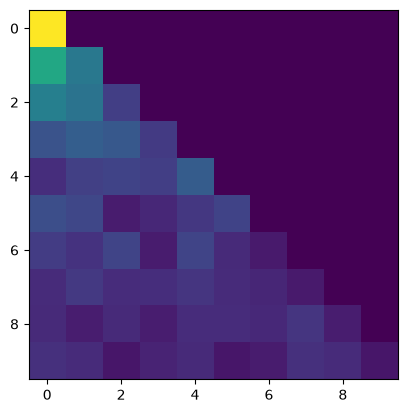

In [11]:
import math
import matplotlib.pyplot as plt

q_proj, k_proj, v_proj = (nn.Linear(h_hidden, h_hidden) for _ in range(3))
q, k, v = q_proj(x_emb), k_proj(x_emb), v_proj(x_emb)

T = len(x)
attn = q @ k.T / math.sqrt(h_hidden)
attn = attn.masked_fill(torch.tril(torch.ones(T, T)) == 0, float("-inf"))
attn = torch.softmax(attn, dim=-1)
out = attn @ v

plt.imshow(attn.detach())
out.shape

## Transformer model

In [12]:
from dataclasses import dataclass

@dataclass
class Config:
    vocab_size: int = len(symbols)
    block_size: int = 128
    n_layer: int = 4
    n_head: int = 4
    n_embd: int = 128
    dropout: float = 0.1


class CausalSelfAttention(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.n_head = c.n_head
        self.qkv = nn.Linear(c.n_embd, 3 * c.n_embd)
        self.proj = nn.Linear(c.n_embd, c.n_embd)
        self.drop = nn.Dropout(c.dropout)
        self.register_buffer("mask", torch.tril(torch.ones(c.block_size, c.block_size)))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        # (B, T, C) -> (B, n_head, T, head_size)
        q, k, v = (t.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) for t in (q, k, v))
        att = q @ k.transpose(-2, -1) / math.sqrt(k.size(-1))
        att = att.masked_fill(self.mask[:T, :T] == 0, float("-inf"))
        att = self.drop(F.softmax(att, dim=-1))
        y = (att @ v).transpose(1, 2).reshape(B, T, C)  # concatenate heads
        return self.drop(self.proj(y))


class Block(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(c.n_embd), nn.LayerNorm(c.n_embd)
        self.attn = CausalSelfAttention(c)
        self.mlp = nn.Sequential(
            nn.Linear(c.n_embd, 4 * c.n_embd), nn.GELU(),
            nn.Linear(4 * c.n_embd, c.n_embd), nn.Dropout(c.dropout),
        )

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x


class GPT(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c = c
        self.tok_emb = nn.Embedding(c.vocab_size, c.n_embd)
        self.pos_emb = nn.Embedding(c.block_size, c.n_embd)
        self.blocks = nn.Sequential(*[Block(c) for _ in range(c.n_layer)])
        self.ln_f = nn.LayerNorm(c.n_embd)
        self.head = nn.Linear(c.n_embd, c.vocab_size)

    def forward(self, idx, targets=None):
        T = idx.size(1)
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))
        logits = self.head(self.ln_f(self.blocks(x)))
        loss = None if targets is None else F.cross_entropy(logits.flatten(0, 1), targets.flatten())
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.c.block_size:])
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = -float("inf")
            idx_next = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

In [ ]:
# T1 T2 ... Tk
#       |
# --- Transformer ---
#       | 

# O1 O2 ... Ok 
#  |  |     |
# T2  T3    T_{k+1}


# BOS -- beginning of sequence


In [13]:
config = Config()
model = GPT(config).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")

0.83M parameters


In [32]:
def sample(prompt, max_new_tokens=300, **kw):
    model.eval()
    idx = torch.tensor([encode(prompt)], device=device)
    return decode(model.generate(idx, max_new_tokens, **kw)[0].tolist())

print(sample("Мавка"))

Мавка барані поробить моя в кижаку з несититаро,
та я прометерчи не пора
зались до моря - гриді!
По так дай я, дречко ж мала
із не Забабув
покили не висту до потна?
Ви-га-хо-го! з не, де ти заборіз. Музь їх, пратив бідне засвітися, мокра біг від пачитом розміє в поміє в баф з канув; на [матів; одядька бр


## Training

In [15]:
batch_size = 32

def get_batch(split):
    d = train_idx if split == "train" else val_idx
    ix = torch.randint(len(d) - config.block_size - 1, (batch_size,))
    x = torch.stack([d[i : i + config.block_size] for i in ix])
    y = torch.stack([d[i + 1 : i + 1 + config.block_size] for i in ix])
    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss(n_batches=20):
    model.eval()
    res = {s: torch.stack([model(*get_batch(s))[1] for _ in range(n_batches)]).mean().item()
           for s in ("train", "val")}
    model.train()
    return res

In [26]:
x, y = batch = get_batch("train")
decode(x[0].cpu().numpy())

'о\nлишиться чорний згар та сивий попіл.\nКоли ж його зневажать, як покидьку,\nвоно лежить і кисне, як солома,\nв воді холодній марно'

In [27]:
max_steps, eval_every = 1500, 100
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.1)
history = []

model.train()
for step in range(max_steps + 1):
    if step % eval_every == 0:
        losses = estimate_loss()
        history.append((step, losses["train"], losses["val"]))
        print(f"step {step:5d}  train {losses['train']:.3f}  val {losses['val']:.3f}")
    x, y = get_batch("train")
    _, loss = model(x, y)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

step     0  train 4.719  val 4.712
step   100  train 2.654  val 2.670
step   200  train 2.559  val 2.599
step   300  train 2.392  val 2.434
step   400  train 2.227  val 2.298
step   500  train 2.122  val 2.216
step   600  train 1.993  val 2.138
step   700  train 1.929  val 2.080
step   800  train 1.844  val 2.030
step   900  train 1.795  val 1.998
step  1000  train 1.724  val 1.962
step  1100  train 1.660  val 1.936
step  1200  train 1.599  val 1.952
step  1300  train 1.548  val 1.923
step  1400  train 1.493  val 1.911
step  1500  train 1.449  val 1.915


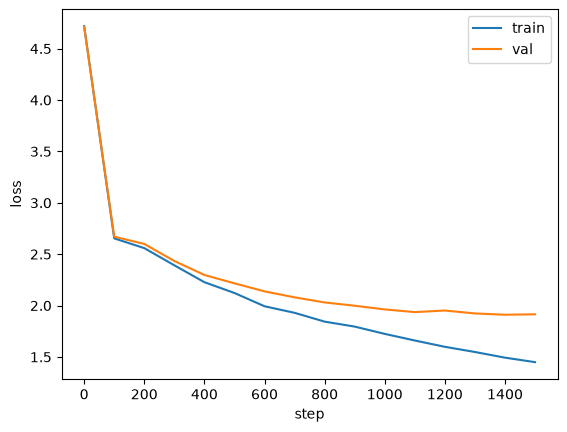

In [29]:
steps, tr, va = zip(*history)
plt.plot(steps, tr, label="train")
plt.plot(steps, va, label="val")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend();

## Inference with sampling

- `temperature < 1` sharpens the distribution (safer, more repetitive), `> 1` flattens it (more random).
- Speaker names in the play are letter-spaced (`М а в к а`), so prompts use the same format.
- `top_k` keeps only the `k` most likely next characters before sampling.

In [33]:
prompt = "М а в к а\n"
for t in (0.5, 0.8, 1.2):
    print(f"--- temperature={t} ---")
    print(sample(prompt, temperature=t, top_k=20))
    print()

--- temperature=0.5 ---
М а в к а
Я була ти не від більше з тебе вибала. Долосько цілу посягі забулись у в лісу, не зрозуміє від серця прозуміє, за други в білим дубкою виду; голова поколись до колоно за вогонько, зборозу призливає воду в до себе полотим в від берегом поструми з листом ваги руки брання в березі, що зо своїми, за роз

--- temperature=0.8 ---
М а в к а
Я й моя знаю..
Л у к а ш
Він ус не знаю.
Перелесник. Золоту.

(З лихає на Мавки ближки до мені дивило)
Не для дубого ж цілу.
Потерчата тут утебе навовчанна?
Л у к а ш
(непочі вставшись)
Ой не з такою?
А то ж він не про на брав до березу!
(Жворо приймікає з плид до рало.
Л у к а ш
(волова)
То все при

--- temperature=1.2 ---
М а в к а
Мені хочеш деться,
бо груйнуй про тепиштих? О шді!..
Як то ще знавим зимулась?
К у ц ь
(головався наючись, до смолоти,
брибігок розмися дубою)
Довиціг літі...
Щіпо коли берега
зійнять сопоного! Ядець,
вкби на навиніз,
та пітлав?
М а в к а
Не жартиває сюди,
брамаю, зівоний тух дітка.
Ось та ще 

In [34]:
from torchinfo import summary

In [35]:
summary(model)

Layer (type:depth-idx)                        Param #
GPT                                           --
├─Embedding: 1-1                              11,520
├─Embedding: 1-2                              16,384
├─Sequential: 1-3                             --
│    └─Block: 2-1                             --
│    │    └─LayerNorm: 3-1                    256
│    │    └─LayerNorm: 3-2                    256
│    │    └─CausalSelfAttention: 3-3          66,048
│    │    └─Sequential: 3-4                   131,712
│    └─Block: 2-2                             --
│    │    └─LayerNorm: 3-5                    256
│    │    └─LayerNorm: 3-6                    256
│    │    └─CausalSelfAttention: 3-7          66,048
│    │    └─Sequential: 3-8                   131,712
│    └─Block: 2-3                             --
│    │    └─LayerNorm: 3-9                    256
│    │    └─LayerNorm: 3-10                   256
│    │    └─CausalSelfAttention: 3-11         66,048
│    │    └─Sequential: 3-12

In [13]:
print(sample("Л у к а ш\nО, як же ти ", max_new_tokens=500, temperature=0.8, top_k=10))

Л у к а ш
О, як же ти знайдутила
до той, щоб не постав собі поважні тепера,
що він побила по чим.
М а в к а
Він не рідні від серці по поластого не бачив знатися по з дерейне над.

М а в к а
Дай світі прихилась видкою драгою.

Л у к а ш
Ти ж не нас не хороже може... Я буду засно жаробок.
М а в к а
Се вже тогоді маю ж бувати!
М а в к а
Се тут маю
які звід вибуденьма на себе вас до прийдеться по равіті...
Він тебе засте, ще покра про по лісі все він простує по не світі пучинать полискадається до озеро, помуваючи до себе
